In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=0.8, random_state=42)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dataset berhasil dibuat dan di-scale. Jumlah data:", X_scaled.shape[0])

Dataset berhasil dibuat dan di-scale. Jumlah data: 500


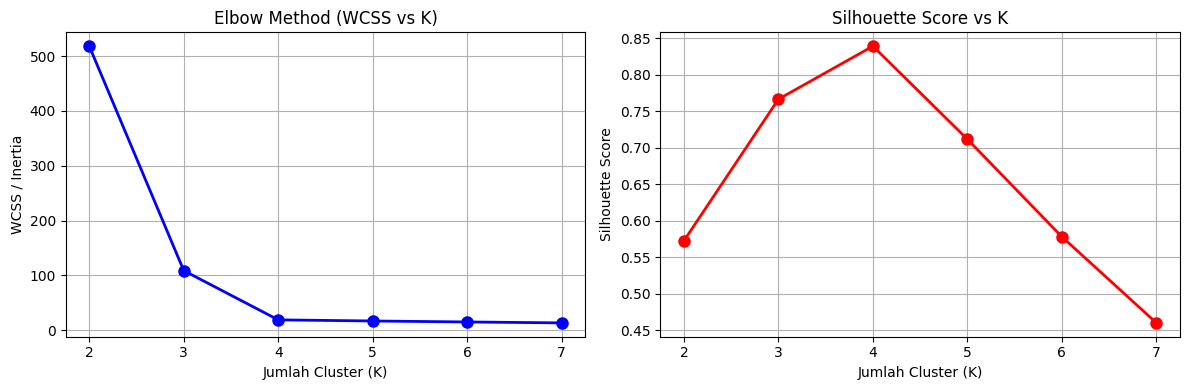

In [2]:
wcss = []
silhouette_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(score)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(K_range, wcss, 'bo-', linewidth=2, markersize=8)
ax[0].set_title('Elbow Method (WCSS vs K)')
ax[0].set_xlabel('Jumlah Cluster (K)')
ax[0].set_ylabel('WCSS / Inertia')
ax[0].grid(True)

ax[1].plot(K_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax[1].set_title('Silhouette Score vs K')
ax[1].set_xlabel('Jumlah Cluster (K)')
ax[1].set_ylabel('Silhouette Score')
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [3]:
weights = np.array([2.5, 1.0])
X_weighted = X_scaled * weights

kmeans_weighted = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_weighted = kmeans_weighted.fit_predict(X_weighted)
centroids = kmeans_weighted.cluster_centers_

print("Clustering dengan Weighted K-Means selesai!")

Clustering dengan Weighted K-Means selesai!


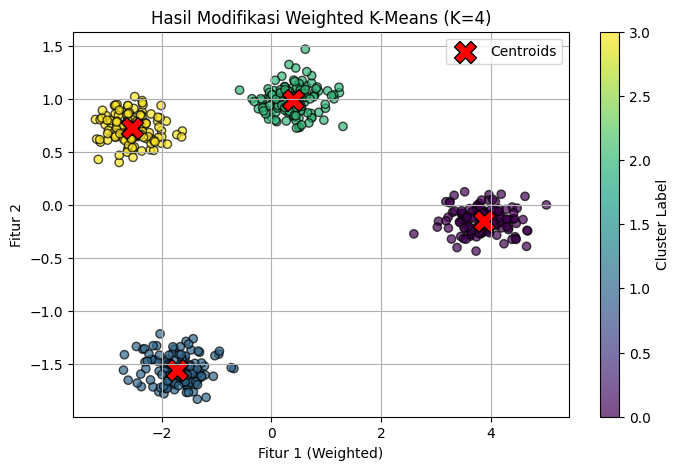

Silhouette Score Akhir: 0.8333


In [4]:
plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_weighted[:, 0], X_weighted[:, 1], c=labels_weighted, cmap='viridis', alpha=0.7, edgecolors='k')
plt.scatter(centroids[:, 0], centroids[:, 1], s=250, c='red', marker='X', label='Centroids', edgecolors='black')

plt.title('Hasil Modifikasi Weighted K-Means (K=4)')
plt.xlabel('Fitur 1 (Weighted)')
plt.ylabel('Fitur 2')
plt.legend()
plt.colorbar(scatter, label='Cluster Label')
plt.grid(True)
plt.show()

final_score = silhouette_score(X_weighted, labels_weighted)
print(f"Silhouette Score Akhir: {final_score:.4f}")